# Your First Neural Network: Fashion-MNIST from Start to Finish

[Open in Colab](https://colab.research.google.com/github/ZhuoranYang/sds265-fall26/blob/main/demos/12-neural-optimization/first-neural-network.ipynb)

This notebook trains a neural network to recognize ten kinds of clothing
from $28\times 28$ grayscale images, and goes through every step of a real
training run:

1. load and look at the data;
2. split off a validation set;
3. build `DataLoader`s;
4. fit a linear baseline;
5. define a multilayer perceptron (MLP) and check it before training;
6. train it with AdamW, tracking training and validation curves;
7. keep the epoch with the best validation accuracy;
8. evaluate once on the test set, with a confusion matrix and a look at the
   mistakes;
9. save the trained model and load it back.

**How to run it.** In Colab, choose Runtime → Run all. Everything runs on a
CPU: the whole notebook takes a few minutes, and no GPU is needed. If a GPU
runtime is selected, the code uses it automatically.

The code follows the conventions of PyTorch's
[Learn the Basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html) tutorials, so you can read the two side by
side.

## 0. Setup

We fix the random seed so that the split, the initialization, and the
shuffling order are the same every time the notebook runs. `device` is
`"cuda"` on a GPU runtime and `"cpu"` otherwise.

In [1]:
import copy
import math
import time
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

SEED = 265
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.8.0 | device: cpu


## 1. The data

Fashion-MNIST was released by Zalando Research as a harder drop-in
replacement for handwritten digits. It has 60,000 training images and 10,000
test images, each with one of ten labels.

`datasets.FashionMNIST` is a `Dataset`: `train_full[i]` returns one pair
$(x_i, y_i)$. The `transform` converts each stored image to a float tensor of
shape `[1, 28, 28]` (one color channel) with pixels scaled to $[0, 1]$. The
first run downloads about 30 MB.

In [2]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
train_full = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

classes = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
x, y = train_full[0]
print("training images:", len(train_full), "| test images:", len(test_data))
print("one image:", tuple(x.shape), x.dtype, f"pixel range [{x.min():.1f}, {x.max():.1f}]")
print("its label:", y, "=", classes[y])
assert len(train_full) == 60_000 and len(test_data) == 10_000
assert x.shape == (1, 28, 28) and 0 <= x.min() and x.max() <= 1

training images: 60000 | test images: 10000
one image: (1, 28, 28) torch.float32 pixel range [0.0, 1.0]
its label: 9 = Ankle boot


Look at the data before modeling it. Each row below shows examples of one
class. Notice which classes look alike: shirts, T-shirts, pullovers, and coats
share a silhouette, and we should expect the model to confuse them.

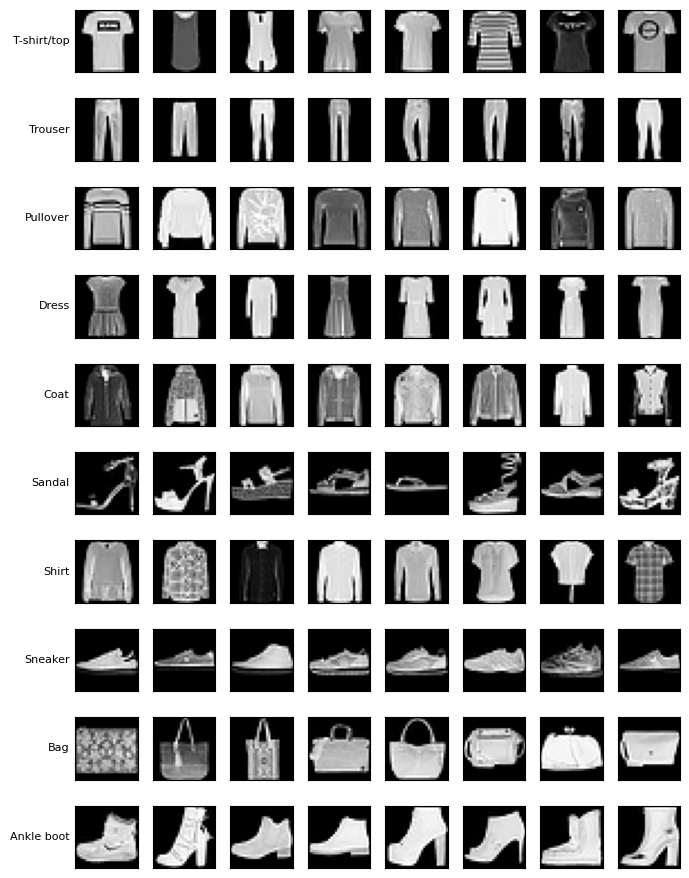

images per class: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]


In [3]:
fig, axes = plt.subplots(10, 8, figsize=(7, 9))
labels = train_full.targets
for c in range(10):
    idx = (labels == c).nonzero().flatten()[:8]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(train_full[i][0].squeeze(), cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(classes[c], rotation=0, ha="right", va="center", fontsize=8)
plt.tight_layout()
plt.show()

print("images per class:", torch.bincount(labels).tolist())

The classes are exactly balanced, 6,000 training images each, so a
classifier that guesses at random is right 10% of the time. That is the
floor every model below must beat.

## 2. Training, validation, and test sets

We use three disjoint sets, each with one job:

| set | size | used for |
|---|---|---|
| training | 54,000 | computing gradients and updating the weights |
| validation | 6,000 | choosing settings and the stopping epoch |
| test | 10,000 | one final, unbiased estimate of accuracy, at the very end |

The test set is touched once. If we picked the epoch or the learning rate by
looking at test accuracy, the test accuracy would no longer estimate
performance on new data: we would have fit it.

In [4]:
generator = torch.Generator().manual_seed(SEED)
train_data, val_data = random_split(train_full, [54_000, 6_000], generator=generator)
print("training:", len(train_data), "| validation:", len(val_data), "| test:", len(test_data))

training: 54000 | validation: 6000 | test: 10000


## 3. DataLoaders

A `DataLoader` groups examples into minibatches. For training, `shuffle=True`
draws a fresh random order every epoch, so each epoch visits every training
image once, in batches of `batch_size`. Validation and test loaders do not
need shuffling.

With $n = 54{,}000$ and $B = 128$ an epoch has $\lceil n/B \rceil = 422$
batches, hence 422 optimizer steps.

In [5]:
batch_size = 128
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=1000)
test_loader = DataLoader(test_data, batch_size=1000)

X, y = next(iter(train_loader))
print("one batch: X", tuple(X.shape), "| y", tuple(y.shape))
print("optimizer steps per epoch:", len(train_loader))
assert len(train_loader) == math.ceil(len(train_data) / batch_size) == 422

one batch: X (128, 1, 28, 28) | y (128,)
optimizer steps per epoch: 422


## 4. Training and evaluation functions

These two functions are reused for every model in the notebook.

`train_one_epoch` makes one pass over the training loader. For each batch it
runs the five lines at the heart of all neural-network training:

```python
pred = model(X)              # forward pass: logits, shape [B, 10]
loss = loss_fn(pred, y)      # average cross-entropy over the batch
optimizer.zero_grad()        # empty every p.grad
loss.backward()              # backpropagation: fill every p.grad
optimizer.step()             # update the weights using p.grad
```

`evaluate` computes the average loss and the accuracy on a loader. It runs
under `torch.no_grad()`, which tells autograd not to record anything: no
gradients are needed for evaluation, and skipping the record saves memory and
time. `model.eval()` and `model.train()` switch layers such as dropout
between their two behaviors; our models have none, but the calls are a good
habit.

In [6]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss, correct, count = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (pred.argmax(1) == y).sum().item()
        count += len(y)
    return total_loss / count, correct / count


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        pred = model(X)
        total_loss += loss_fn(pred, y).item() * len(y)
        correct += (pred.argmax(1) == y).sum().item()
        count += len(y)
    return total_loss / count, correct / count


def fit(model, epochs, lr=1e-3, weight_decay=0.01):
    """Train with AdamW; return the history and the best-validation weights."""
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state, best_epoch = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[key].append(value)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        print(f"epoch {epoch:2d} | train loss {train_loss:.3f} acc {train_acc:.3f} "
              f"| val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time() - start:.1f} s")
    print(f"best validation accuracy {best_acc:.3f} at epoch {best_epoch}")
    return history, best_state

## 5. A linear baseline

Before building a network, fit the simplest model that could work:
multinomial logistic regression, which is one linear layer from the 784
pixels to the 10 class scores. `nn.Flatten()` turns each `[1, 28, 28]` image
into a vector of length 784.

`nn.CrossEntropyLoss` takes the raw scores (logits) and applies the softmax
internally, so the model does not end with a softmax. Its value is the
multiclass logistic loss from the classification lectures.

In [7]:
torch.manual_seed(SEED)
linear = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 10)).to(device)
print("parameters:", sum(p.numel() for p in linear.parameters()))
linear_history, _ = fit(linear, epochs=5)

parameters: 7850


epoch  1 | train loss 0.744 acc 0.760 | val loss 0.568 acc 0.812 | 3.6 s


epoch  2 | train loss 0.518 acc 0.828 | val loss 0.512 acc 0.827 | 3.5 s


epoch  3 | train loss 0.477 acc 0.840 | val loss 0.486 acc 0.837 | 3.5 s


epoch  4 | train loss 0.455 acc 0.846 | val loss 0.469 acc 0.841 | 3.5 s


epoch  5 | train loss 0.441 acc 0.851 | val loss 0.469 acc 0.838 | 3.7 s
best validation accuracy 0.841 at epoch 4


A linear model already gets well above the 10% floor. The question for
the network is how much a nonlinear model adds.

## 6. The multilayer perceptron

Our network has two hidden layers with ReLU activations:
$$
784 \xrightarrow{\ \text{Linear}\ } 256 \xrightarrow{\text{ReLU}}
\xrightarrow{\ \text{Linear}\ } 128 \xrightarrow{\text{ReLU}}
\xrightarrow{\ \text{Linear}\ } 10 .
$$
Each `nn.Linear(d_in, d_out)` holds a weight matrix of shape `[d_out, d_in]`
and a bias of length `d_out`; PyTorch initializes them randomly at
construction.

In [8]:
class MLP(nn.Module):
    def __init__(self, hidden=(256, 128)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], 10),
        )

    def forward(self, x):
        return self.net(x)


torch.manual_seed(SEED)
model = MLP().to(device)
for name, p in model.named_parameters():
    print(f"{name:14s} {str(tuple(p.shape)):12s} {p.numel():>7,d}")
print(f"total parameters: {sum(p.numel() for p in model.parameters()):,d}")

net.1.weight   (256, 784)   200,704
net.1.bias     (256,)           256
net.3.weight   (128, 256)    32,768
net.3.bias     (128,)           128
net.5.weight   (10, 128)      1,280
net.5.bias     (10,)             10
total parameters: 235,146


**Check the model before training it.** Two quick tests catch most
setup bugs.

1. *Shapes.* A batch of 128 images should give logits of shape `[128, 10]`.
2. *The initial loss.* An untrained network with small random weights gives
   nearly equal probability $1/10$ to every class, so its cross-entropy should
   be close to $-\log(1/10) = \log 10 \approx 2.303$. A very different value
   means a bug in the data, the labels, or the loss.

In [9]:
X, y = next(iter(train_loader))
X, y = X.to(device), y.to(device)
with torch.no_grad():
    logits = model(X)
    probs = logits.softmax(dim=1)
print("logits:", tuple(logits.shape))
print("predicted probabilities for the first image:", [round(p, 3) for p in probs[0].tolist()])
initial_loss = nn.CrossEntropyLoss()(logits, y).item()
print(f"initial loss {initial_loss:.3f}  vs  log 10 = {math.log(10):.3f}")
assert logits.shape == (128, 10)
assert abs(initial_loss - math.log(10)) < 0.1, "initial loss far from log 10: check data and labels"


logits: (128, 10)
predicted probabilities for the first image: [0.098, 0.108, 0.1, 0.099, 0.104, 0.095, 0.099, 0.106, 0.095, 0.095]
initial loss 2.299  vs  log 10 = 2.303


Both checks pass: the logits have one row per image and one column per
class, and the loss of the untrained network is within a few thousandths of
$\log 10$. The predicted probabilities above are all close to $0.1$, which is
what "no information yet" looks like.

## 7. Train the network

We train for 15 epochs with AdamW at learning rate $10^{-3}$ and weight
decay $0.01$, the defaults that work for most small networks. Each line
reports one epoch. `fit` also keeps a copy of the weights from the epoch with
the best validation accuracy.

In [10]:
history, best_state = fit(model, epochs=15)

epoch  1 | train loss 0.579 acc 0.800 | val loss 0.445 acc 0.839 | 4.0 s


epoch  2 | train loss 0.401 acc 0.857 | val loss 0.387 acc 0.860 | 3.8 s


epoch  3 | train loss 0.358 acc 0.869 | val loss 0.365 acc 0.872 | 4.1 s


epoch  4 | train loss 0.328 acc 0.880 | val loss 0.352 acc 0.873 | 3.8 s


epoch  5 | train loss 0.306 acc 0.888 | val loss 0.344 acc 0.878 | 3.8 s


...

epoch 11 | train loss 0.234 acc 0.911 | val loss 0.324 acc 0.891 | 4.1 s


epoch 12 | train loss 0.226 acc 0.915 | val loss 0.325 acc 0.892 | 3.8 s


epoch 13 | train loss 0.216 acc 0.918 | val loss 0.315 acc 0.892 | 3.9 s


epoch 14 | train loss 0.208 acc 0.921 | val loss 0.323 acc 0.893 | 4.3 s


epoch 15 | train loss 0.201 acc 0.923 | val loss 0.328 acc 0.890 | 4.3 s
best validation accuracy 0.893 at epoch 14


Read the log row by row. The training loss falls every epoch. The
validation accuracy rises quickly for the first few epochs and then creeps
up by a few tenths of a percent at a time, while the training accuracy keeps
climbing: the network is starting to fit details of its own training images
that do not carry over to new ones. The plot below makes this visible.

## 8. Learning curves

Plot the training and validation loss and accuracy against the epoch. Three
things to look for:

- **Is the training loss still falling?** If so, more epochs could help.
- **The gap between training and validation.** Training accuracy keeps rising
  as the network fits its own training images more closely; validation
  accuracy levels off. A widening gap is overfitting.
- **Validation loss rising while validation accuracy holds.** The network is
  becoming overconfident on the examples it gets wrong. This is a common
  early sign of overfitting.

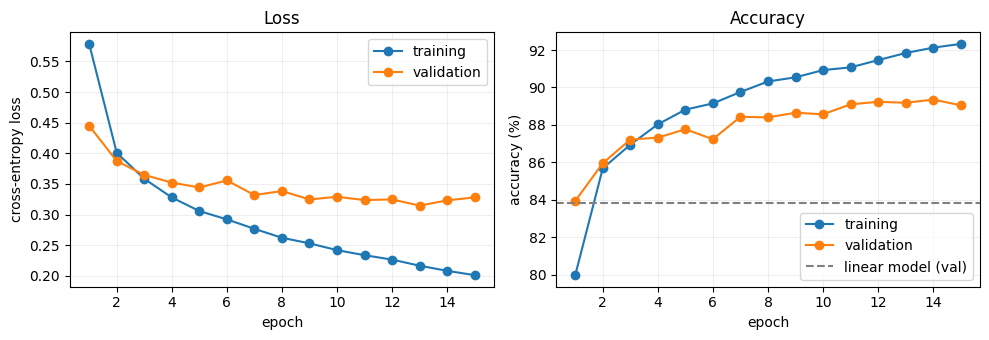

In [11]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(epochs, history["train_loss"], "o-", label="training")
ax1.plot(epochs, history["val_loss"], "o-", label="validation")
ax1.set(xlabel="epoch", ylabel="cross-entropy loss", title="Loss")
ax2.plot(epochs, [100 * a for a in history["train_acc"]], "o-", label="training")
ax2.plot(epochs, [100 * a for a in history["val_acc"]], "o-", label="validation")
ax2.axhline(100 * linear_history["val_acc"][-1], color="gray", ls="--", label="linear model (val)")
ax2.set(xlabel="epoch", ylabel="accuracy (%)", title="Accuracy")
for ax in (ax1, ax2):
    ax.grid(alpha=0.2); ax.legend()
plt.tight_layout()
plt.show()

## 9. Final evaluation on the test set

We restore the weights from the best validation epoch (a simple form of
**early stopping**) and evaluate on the test set, once.

In [12]:
model.load_state_dict(best_state)
loss_fn = nn.CrossEntropyLoss()
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
lin_test_loss, lin_test_acc = evaluate(linear, test_loader, loss_fn)
print(f"MLP    test accuracy: {100 * test_acc:.1f}%   (test loss {test_loss:.3f})")
print(f"linear test accuracy: {100 * lin_test_acc:.1f}%   (test loss {lin_test_loss:.3f})")

MLP    test accuracy: 88.6%   (test loss 0.333)
linear test accuracy: 83.4%   (test loss 0.476)


### The confusion matrix

Accuracy is one number. The **confusion matrix** shows where the errors go:
entry $(i, j)$ counts test images of true class $i$ that the model labeled
$j$. The diagonal holds the correct predictions.

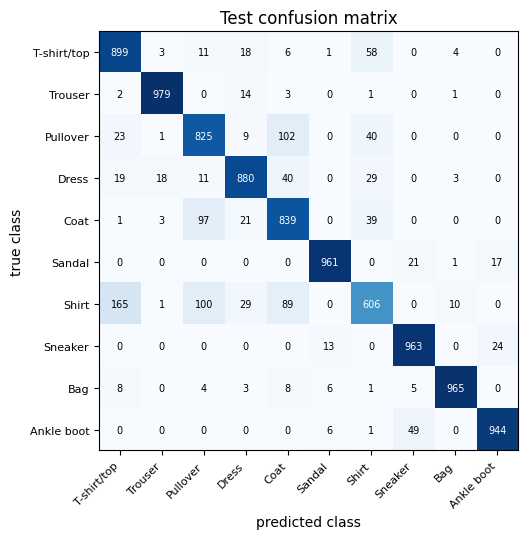

Shirt        60.6%
Pullover     82.5%
Coat         83.9%
Dress        88.0%
T-shirt/top  89.9%
Ankle boot   94.4%
Sandal       96.1%
Sneaker      96.3%
Bag          96.5%
Trouser      97.9%


In [13]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, probs, labels = [], [], []
    for X, y in loader:
        p = model(X.to(device)).softmax(dim=1).cpu()
        probs.append(p); preds.append(p.argmax(1)); labels.append(y)
    return torch.cat(preds), torch.cat(probs), torch.cat(labels)


preds, probs, labels = predict(model, test_loader)
confusion = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(labels, preds):
    confusion[t, p] += 1

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(confusion, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, confusion[i, j].item(), ha="center", va="center", fontsize=7,
                color="white" if confusion[i, j] > confusion.max() / 2 else "black")
ax.set_xticks(range(10), classes, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(10), classes, fontsize=8)
ax.set(xlabel="predicted class", ylabel="true class", title="Test confusion matrix")
plt.tight_layout()
plt.show()

per_class = confusion.diag() / confusion.sum(1)
for c in per_class.argsort():
    print(f"{classes[c]:12s} {100 * per_class[c]:.1f}%")

The hardest class is usually *Shirt*, confused with T-shirt/top,
Pullover, and Coat: the classes we expected to be confused when we first
looked at the images. Footwear and trousers are nearly perfect.

### The mistakes

The most informative errors are the confident ones. Below are the test images
the model got wrong with the highest predicted probability, labeled
*predicted (probability) / true*.

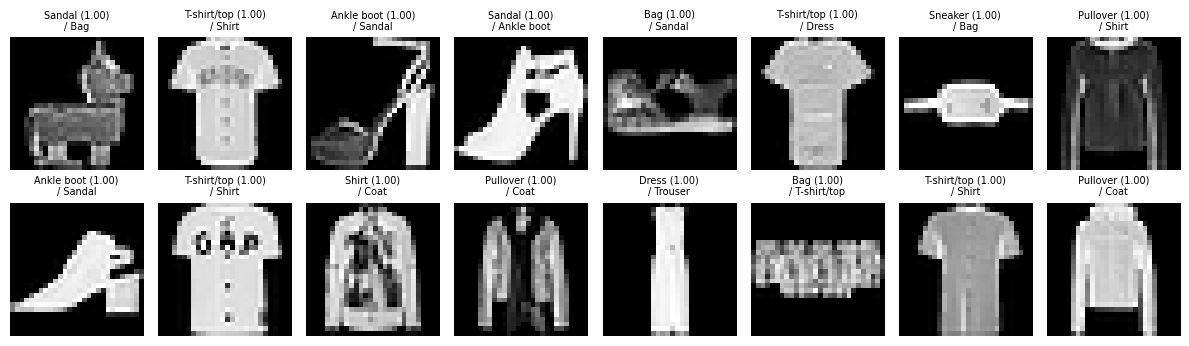

In [14]:
wrong = (preds != labels).nonzero().flatten()
confidence = probs[wrong, preds[wrong]]
worst = wrong[confidence.argsort(descending=True)[:16]]

fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for ax, i in zip(axes.flat, worst):
    ax.imshow(test_data[i][0].squeeze(), cmap="gray")
    ax.set_title(f"{classes[preds[i]]} ({probs[i, preds[i]]:.2f})\n/ {classes[labels[i]]}", fontsize=7)
    ax.axis("off")
plt.tight_layout()
plt.show()

Some of these labels are debatable even for a person. That is a useful
reminder: test accuracy is limited by the data as well as by the model.

### One prediction, in detail

The network outputs a probability for every class. For a single test image:

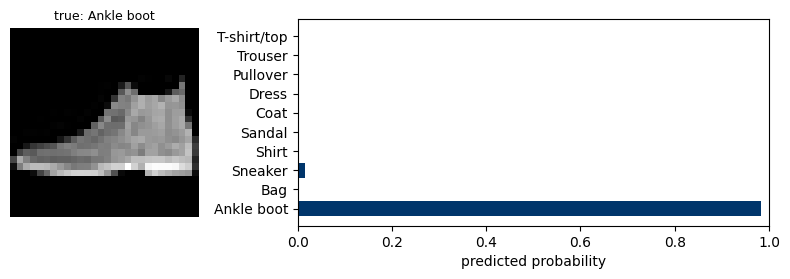

In [15]:
i = 0
image, label = test_data[i]
with torch.no_grad():
    p = model(image.unsqueeze(0).to(device)).softmax(dim=1).squeeze().cpu()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 2.8), gridspec_kw={"width_ratios": [1, 2.5]})
ax1.imshow(image.squeeze(), cmap="gray"); ax1.axis("off")
ax1.set_title(f"true: {classes[label]}", fontsize=9)
ax2.barh(classes, p.numpy(), color="#00356B")
ax2.set(xlim=(0, 1), xlabel="predicted probability")
ax2.invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Save and load the model

A trained model is its `state_dict()`: a dictionary from parameter names to
tensors. Saving it and loading it into a freshly constructed `MLP` gives back
exactly the same predictions. (To *resume training* later you would also save
`optimizer.state_dict()`, which holds AdamW's moment estimates.)

In [16]:
torch.save(model.state_dict(), "fashion_mlp.pt")

restored = MLP().to(device)
restored.load_state_dict(torch.load("fashion_mlp.pt", map_location=device))
_, restored_acc = evaluate(restored, test_loader, loss_fn)
print(f"restored model test accuracy: {100 * restored_acc:.1f}%")
assert restored_acc == test_acc

restored model test accuracy: 88.6%


## 11. Summary

| step | what we did |
|---|---|
| data | a `Dataset` of $(x_i, y_i)$ pairs, split into training, validation, and test |
| batches | a shuffling `DataLoader`: one epoch = 422 optimizer steps |
| baseline | a linear model, for a reference accuracy |
| model | an MLP with two hidden layers, checked by shapes and the initial loss $\approx \log 10$ |
| training | forward, loss, `zero_grad`, `backward`, `step`, with AdamW |
| selection | the epoch with the best **validation** accuracy |
| evaluation | the **test** set, once: accuracy, confusion matrix, mistakes |

## 12. Experiments to try

Change one thing at a time, rerun from Section 6, and compare the
*validation* accuracy, keeping the test set for the very end.

1. **Learning rate.** Try `lr=1e-2` and `lr=1e-4` in `fit`. Which is too
   large, which too small, and how can you tell from the curves?
2. **Width and depth.** Try `MLP(hidden=(64, 32))` and
   `MLP(hidden=(1024, 512))`. How do the parameter count, the time per epoch,
   and the train–validation gap change?
3. **Batch size.** Set `batch_size = 32` or `512` and rebuild the loaders.
   How many steps does an epoch take, and what happens to accuracy after the
   same number of *epochs*?
4. **Optimizer.** In `fit`, replace AdamW by
   `torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9)`.
5. **Dropout.** Add `nn.Dropout(0.2)` after each `nn.ReLU()`. Does the gap
   between training and validation accuracy shrink?
6. **No shuffling.** Set `shuffle=False` in the training loader. What changes?